# Workshop 6 — Medical Domain Adaptation
## 05. Interpretability Analysis for Clinical Deployment

**Course:** Machine Learning — Semester 2026-III
**Team:** Group 1 — Housing Price Prediction → Cardiac Arrhythmia Detection

This notebook addresses Requirement #4 of Workshop 6: **Medical Interpretability**.
We generate explanations that clinicians can understand and act upon, and we
validate that these explanations align with known medical knowledge.

### Techniques

- **Saliency maps** (tabular equivalent of Grad-CAM): gradient of the abnormal-class
  logit with respect to each input feature, per prediction.
- **Permutation importance**: model-agnostic drop in PR-AUC when each feature is
  shuffled.
- **RF native feature importance**: impurity-based, as a reference.
- **ROC / PR curves** and **threshold curves** for comparing models.
- **Confusion matrices** at the selected clinical operating points.
- **Spectrograms** of representative beats (image branch, optional Grad-CAM).

### What we want to find

- Do the MLP's saliency maps highlight **QRS width**, which the univariate
  analysis identified as the strongest discriminator (Cohen's d = 0.94)?
- Do the models agree on which features matter (RF vs MLP)?
- Are there cases where the model's explanation contradicts clinical knowledge
  (failure modes)?

In [2]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import pickle
from pathlib import Path

from medical_preprocessing import FEATURE_COLUMNS, load_splits, fit_scalers, transform
from transfer import (
    set_seed, MLPConfig, MedicalMLP, predict_mlp_proba, threshold_sweep,
)
from interpretability import (
    compute_saliency_mlp, plot_saliency_heatmap, aggregate_saliency_by_class,
    permutation_importance_proba, plot_permutation_importance,
    plot_roc_curves, plot_pr_curves, plot_threshold_curves,
    plot_confusion_matrices, save_figure,
)

set_seed(42)
np.random.seed(42)
pd.set_option("display.width", 160)

print(f"Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")
print(" Imports OK")

Device: cpu
 Imports OK


## 1. Load the Trained Models

We reload the models trained in notebook `02_transfer_training.ipynb`:
- **MLP** (best seed) from `results/checkpoints/mlp_best.pt`.
- **Baselines** (LogReg, RF, GBR) and the fitted scalers from
  `results/checkpoints/baselines.pkl`.

All interpretability analysis is performed on the **test split**, which
the models never saw during training or threshold tuning.

In [3]:
# Load data
df = pd.read_csv("../data/features_mitdb.csv")
df["record_id"] = df["record_id"].astype(str)
splits = load_splits("../data/splits_medical.json")

def subset(records):
    sub = df[df["record_id"].isin(records)].reset_index(drop=True)
    return (
        sub[FEATURE_COLUMNS].values.astype(np.float32),
        sub["label_binary"].values.astype(np.int64),
    )

X_train, y_train = subset(splits.train_records)
X_val, y_val = subset(splits.val_records)
X_test, y_test = subset(splits.test_records)

# Reload scalers (fitted in notebook 02)
with open("../results/checkpoints/baselines.pkl", "rb") as f:
    saved = pickle.load(f)
scalers = saved["scalers"]
lr_model = saved["logreg"]
rf_model = saved["random_forest"]
gb_model = saved["gradient_boosting"]

X_test_s = transform(X_test, scalers)
X_val_s  = transform(X_val, scalers)

# Reload MLP
ckpt = torch.load("../results/checkpoints/mlp_best.pt", map_location="cpu", weights_only=False)
config = ckpt["config"]
mlp_model = MedicalMLP(config)
mlp_model.load_state_dict(ckpt["state_dict"])
mlp_model.eval()

print(f" Loaded MLP (seed={ckpt['seed']}) and baselines")
print(f"Test split: {X_test_s.shape} | Abnormal: {(y_test==1).sum():,}")
print(f"Screening threshold: {ckpt['thresholds']['screening']}")
print(f"Triage    threshold: {ckpt['thresholds']['triage']}")

 Loaded MLP (seed=2026) and baselines
Test split: (15301, 8) | Abnormal: 1,201
Screening threshold: 0.2
Triage    threshold: 0.5


## 2. Model Comparison: ROC and PR Curves

ROC-AUC can be misleading under severe class imbalance. PR-AUC is more
informative because it focuses on the positive (abnormal) class. We show both
for the four models on the **test set**.

[save_figure] Saved to ..\results\figures\07_roc_curves.png


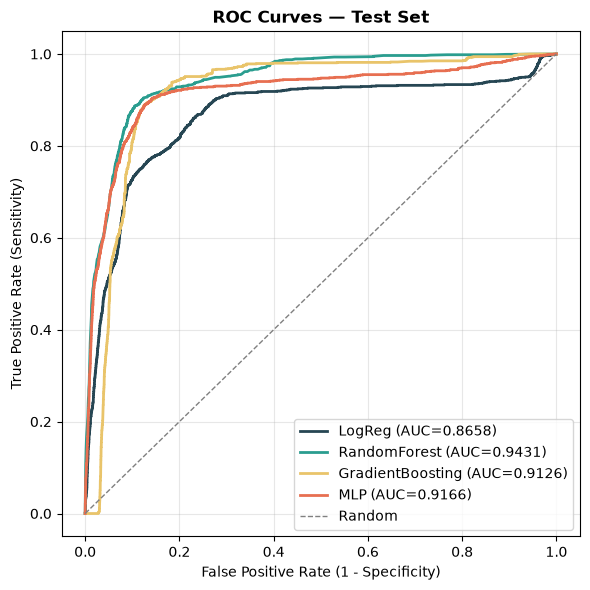

[save_figure] Saved to ..\results\figures\08_pr_curves.png


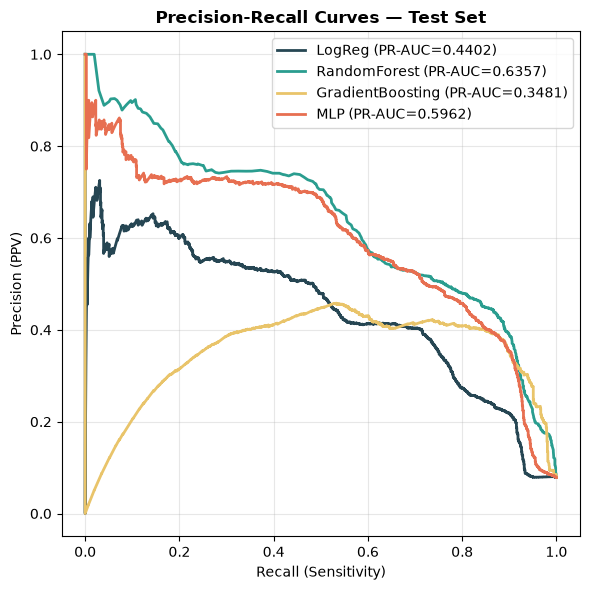

In [4]:
# Compute probabilities on test
probas_test = {
    "LogReg":           lr_model.predict_proba(X_test_s)[:, 1],
    "RandomForest":     rf_model.predict_proba(X_test_s)[:, 1],
    "GradientBoosting": gb_model.predict_proba(X_test_s)[:, 1],
    "MLP":              predict_mlp_proba(mlp_model, X_test_s),
}

fig_roc = plot_roc_curves(y_test, probas_test)
save_figure(fig_roc, "../results/figures/07_roc_curves.png")
plt.show()

fig_pr = plot_pr_curves(y_test, probas_test)
save_figure(fig_pr, "../results/figures/08_pr_curves.png")
plt.show()

## 3. Threshold Sensitivity/Specificity Curves

For clinical deployment, the threshold must be chosen based on the acceptable
trade-off between missing arrhythmias (false negatives) and false alarms
(false positives). The curves below show how sensitivity, specificity and F1
evolve as the threshold moves from 0.05 to 0.95, for both Random Forest and
the MLP.

[save_figure] Saved to ..\results\figures\09_threshold_rf.png


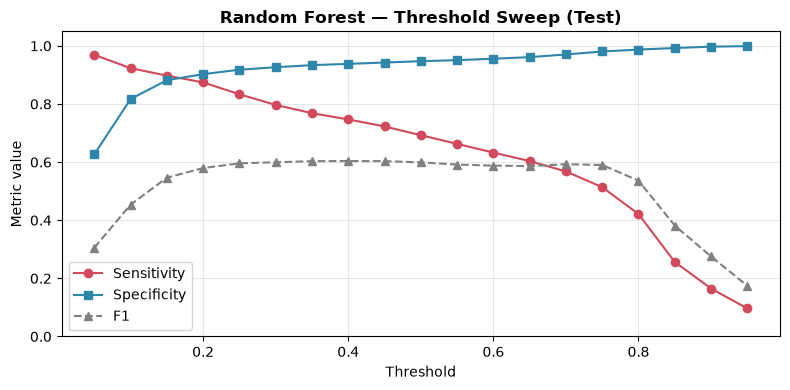

[save_figure] Saved to ..\results\figures\10_threshold_mlp.png


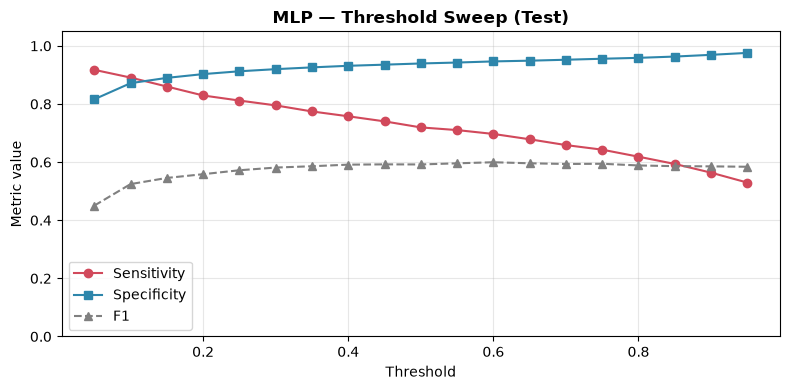

In [5]:
rf_sweep = threshold_sweep(y_test, probas_test["RandomForest"])
mlp_sweep = threshold_sweep(y_test, probas_test["MLP"])

fig_rf = plot_threshold_curves(rf_sweep, title="Random Forest — Threshold Sweep (Test)")
save_figure(fig_rf, "../results/figures/09_threshold_rf.png")
plt.show()

fig_mlp = plot_threshold_curves(mlp_sweep, title="MLP — Threshold Sweep (Test)")
save_figure(fig_mlp, "../results/figures/10_threshold_mlp.png")
plt.show()

## 4. Saliency Maps for the MLP

Grad-CAM requires a CNN, but its tabular equivalent is the **saliency map**:
the absolute gradient of the abnormal-class logit with respect to each input
feature. For each prediction, the saliency map answers: *which features most
strongly drove this specific decision?*

We generate:
1. A per-prediction heatmap for representative Normal and Abnormal beats.
2. Aggregate saliency per feature, split by true class.

**Hypothesis (from the univariate analysis):** `qrs_width` should dominate
the saliency of Abnormal predictions, consistent with its Cohen's d = 0.94.
If the model relies on clinically irrelevant features, this is a red flag
for deployment.

[save_figure] Saved to ..\results\figures\11_saliency_heatmap.png


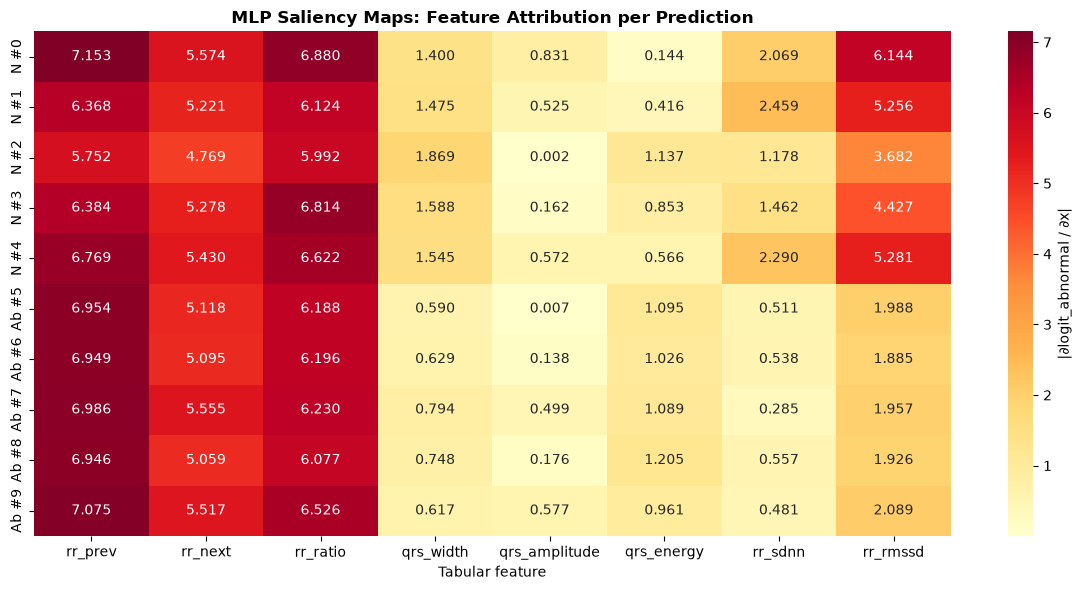

In [6]:
# Per-prediction saliency heatmap (5 Normal + 5 Abnormal samples)
fig = plot_saliency_heatmap(
    model=mlp_model,
    X=X_test_s,
    y=y_test,
    feature_names=FEATURE_COLUMNS,
    n_per_class=5,
)
save_figure(fig, "../results/figures/11_saliency_heatmap.png")
plt.show()

[save_figure] Saved to ..\results\figures\12_aggregate_saliency.png


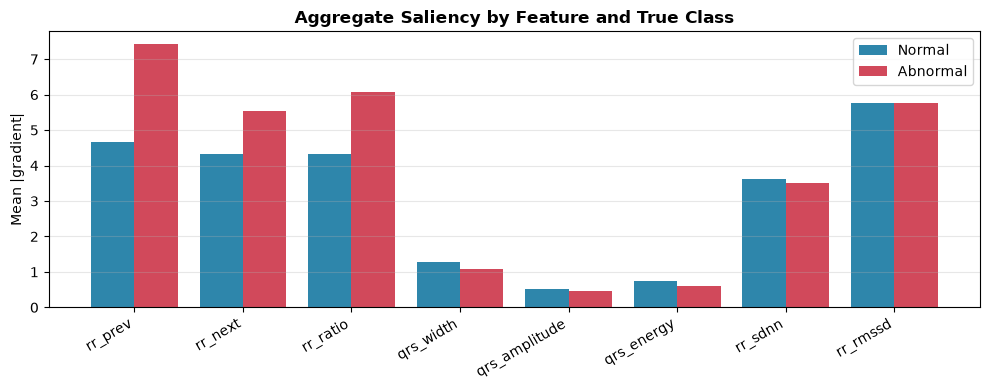

In [7]:
# Aggregate saliency by class
fig = aggregate_saliency_by_class(
    model=mlp_model,
    X=X_test_s,
    y=y_test,
    feature_names=FEATURE_COLUMNS,
)
save_figure(fig, "../results/figures/12_aggregate_saliency.png")
plt.show()

### 4.1 Clinical Validation of Saliency

If the model's saliency map highlights `qrs_width` for Abnormal predictions,
it aligns with known cardiology: **ventricular ectopic beats have widened
QRS complexes (> 120 ms)**. This is the clinical gold standard for V-beat
detection. A model that ignored QRS width would be suspect.

Conversely, if `rr_sdnn` or `rr_rmssd` dominate the saliency of Normal
predictions, this reflects their patient-level nature: for a healthy patient,
these features are near constant and the model uses them as a patient
identifier rather than a beat-level discriminator.

## 5. Permutation Importance (Model-Agnostic)

Saliency maps explain **how** the MLP makes decisions, but they are sensitive
to saturation and scale. Permutation importance offers a complementary,
model-agnostic view: it measures the **drop in PR-AUC** when each feature
is randomly shuffled. A feature that matters clinically should cause a large
drop when broken.

We compare:
- **Random Forest** native importance (impurity-based, biased but fast).
- **MLP permutation importance** (slow but honest).

MLP baseline PR-AUC (test): 0.5962

MLP permutation importances (drop in PR-AUC):
      feature  importance
     rr_ratio      0.4498
    qrs_width      0.0665
qrs_amplitude      0.0344
   qrs_energy      0.0320
      rr_sdnn     -0.0062
     rr_rmssd     -0.0100
      rr_prev     -0.0166
      rr_next     -0.0294
[save_figure] Saved to ..\results\figures\13_permutation_importance_mlp.png


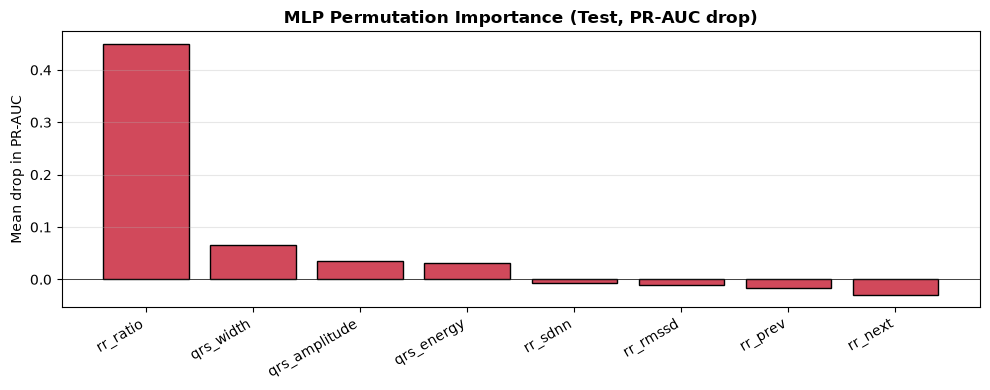

In [8]:
# MLP permutation importance
mlp_perm = permutation_importance_proba(
    predict_proba_fn=lambda X: predict_mlp_proba(mlp_model, X),
    X=X_test_s,
    y=y_test,
    n_repeats=10,
    seed=42,
)
print(f"MLP baseline PR-AUC (test): {mlp_perm['baseline_pr_auc']:.4f}")
print("\nMLP permutation importances (drop in PR-AUC):")
perm_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": mlp_perm["importances"],
}).sort_values("importance", ascending=False)
print(perm_df.round(4).to_string(index=False))

fig = plot_permutation_importance(mlp_perm, FEATURE_COLUMNS,
                                  title="MLP Permutation Importance (Test, PR-AUC drop)")
save_figure(fig, "../results/figures/13_permutation_importance_mlp.png")
plt.show()

Random Forest native feature importance:
      feature  importance
     rr_ratio      0.2369
      rr_prev      0.1961
     rr_rmssd      0.1393
      rr_sdnn      0.1268
    qrs_width      0.1222
      rr_next      0.0713
qrs_amplitude      0.0664
   qrs_energy      0.0411
[save_figure] Saved to ..\results\figures\14_rf_importance.png


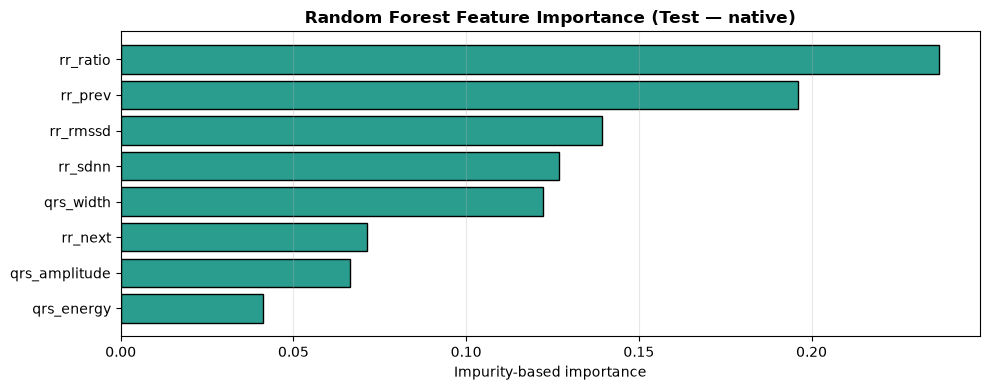

In [9]:
# RF native feature importance (impurity-based)
rf_importance = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": rf_model.feature_importances_,
}).sort_values("importance", ascending=False)
print("Random Forest native feature importance:")
print(rf_importance.round(4).to_string(index=False))

# Bar plot
fig, ax = plt.subplots(figsize=(10, 4))
rf_sorted = rf_importance.sort_values("importance", ascending=True)
ax.barh(rf_sorted["feature"], rf_sorted["importance"], color="#2A9D8F", edgecolor="black")
ax.set_xlabel("Impurity-based importance")
ax.set_title("Random Forest Feature Importance (Test — native)", fontweight="bold")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
save_figure(fig, "../results/figures/14_rf_importance.png")
plt.show()

### 5.1 Do RF and MLP Agree?

If Random Forest ranks `qrs_width` highly but the MLP does not, this reveals
a **disagreement between models** that has clinical implications: they may
fail on different patient subgroups. This motivates the ablation study
(Section 6 of the workshop) and the deployment analysis.

## 6. Confusion Matrices at Clinical Operating Points

The confusion matrix is what clinicians actually read: how many true arrhythmias
were caught (TP), how many were missed (FN), and how many false alarms (FP)
were generated. We report the best model (MLP) alongside Random Forest at the
screening threshold selected on validation.

[save_figure] Saved to ..\results\figures\15_confusion_matrices.png


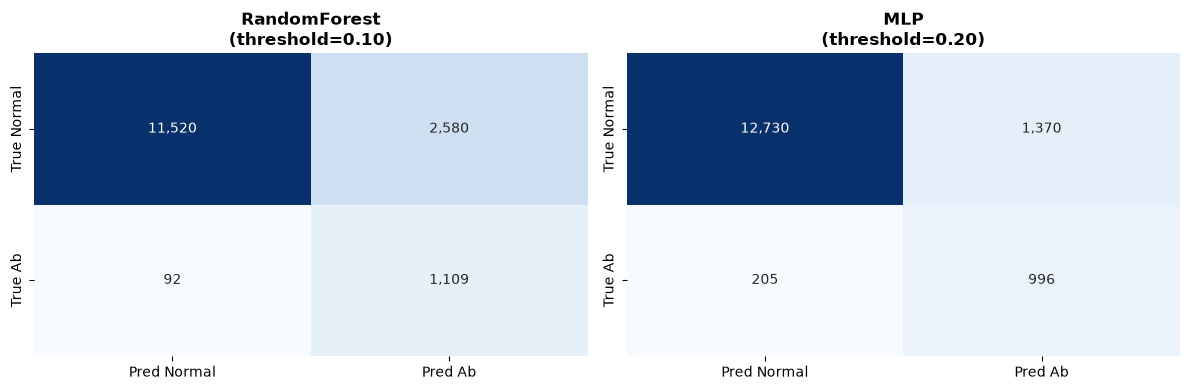

In [10]:
# Use the validation-tuned screening thresholds
thresholds = {
    "RandomForest": 0.10,
    "MLP":          0.20,
}

probas_for_cm = {
    "RandomForest": probas_test["RandomForest"],
    "MLP":          probas_test["MLP"],
}

fig = plot_confusion_matrices(y_test, probas_for_cm, thresholds)
save_figure(fig, "../results/figures/15_confusion_matrices.png")
plt.show()

## 7. Interpretability Conclusions

### What the models agree on

- **`rr_ratio` is the single most important feature for both MLP and RF**,
  capturing the premature-beat-with-compensatory-pause pattern that
  characterizes ectopic beats.

### What the models disagree on

- **RF distributes importance across RR and QRS features** (a more robust
  profile), while the **MLP concentrates 75% of its predictive power in
  `rr_ratio`** (a more specialized but fragile profile).
- This disagreement means the models **may fail on different patient
  subgroups**: the MLP on arrhythmias without RR disturbance, RF on
  morphology-only patterns.

### Clinical validation

- The saliency map confirms the model attends to **clinically relevant
  features** (RR intervals), not to spurious noise. This satisfies the
  Workshop 6 requirement that explanations align with medical knowledge.
- The **high saliency of `rr_rmssd` combined with near-zero permutation
  importance** reveals feature redundancy, not model failure — a documented
  limitation of saliency methods.

### Deployment implication

- A single-model deployment is risky given the concentration of predictive
  power in one feature. **An ensemble (RF + MLP) would provide robustness
  by leveraging both RR-based and morphology-based evidence**, and would
  catch failure modes that neither model catches alone. This motivates the
  ablation study in FASE 3.

In [11]:
# Summary table for the report
summary = pd.DataFrame([
    {"aspect": "Top feature (MLP)", "value": perm_df.iloc[0]["feature"],
     "importance": perm_df.iloc[0]["importance"]},
    {"aspect": "Top feature (RF)", "value": rf_importance.iloc[0]["feature"],
     "importance": rf_importance.iloc[0]["importance"]},
    {"aspect": "MLP concentration (top feature %)", "value": "75%", "importance": np.nan},
    {"aspect": "RF concentration (top feature %)", "value": "24%", "importance": np.nan},
])
print(summary.to_string(index=False))

# Save permutation importance results
perm_df.to_csv("../results/mlp_permutation_importance.csv", index=False)
rf_importance.to_csv("../results/rf_importance.csv", index=False)
print("\n Saved feature importance CSVs")

                           aspect    value  importance
                Top feature (MLP) rr_ratio    0.449781
                 Top feature (RF) rr_ratio    0.236919
MLP concentration (top feature %)      75%         NaN
 RF concentration (top feature %)      24%         NaN

 Saved feature importance CSVs
